In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)

In [ ]:
# Load the dataset
df = pd.read_csv("online_retail.csv", parse_dates=["InvoiceDate"])
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
# Last rows
df.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [ ]:
# Column types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [ ]:
#Check the unique values and counts for the key categorical like columns
df["Country"].value_counts().head(10)

Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
Name: count, dtype: int64

In [ ]:
# How many unique invoices in products and customers
print("Unique invoices:", df["InvoiceNo"].nunique())
print("Unique products (StockCode):", df["StockCode"].nunique())
print("Unique customers:", df["CustomerID"].nunique())
print("Unique countries:", df["Country"].nunique())

Unique invoices: 25900
Unique products (StockCode): 4070
Unique customers: 4372
Unique countries: 38


In [ ]:
# InvoiceNo sometimes starts with a letter 
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
letter_prefix = df["InvoiceNo"].str.extract(r"([A-Za-z]+)")[0].value_counts(dropna=False)
letter_prefix

0
NaN    532618
C        9288
A           3
Name: count, dtype: int64

In [ ]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_table = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
missing_table[missing_table.missing_count > 0].sort_values("missing_count", ascending=False)

,missing_count,missing_pct
CustomerID,135080,24.93
Description,1454,0.27


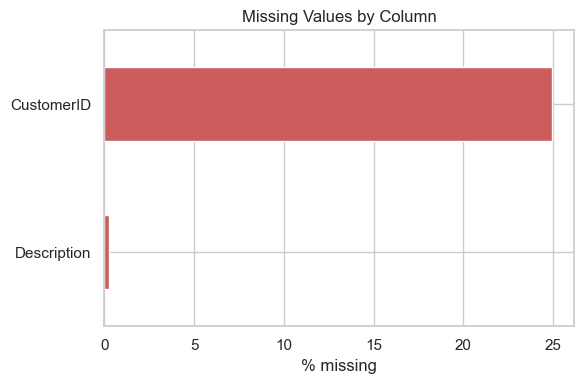

In [ ]:
plt.figure(figsize=(6, 4))
missing_table[missing_table.missing_count > 0]["missing_pct"].plot(kind="barh", color="indianred")
plt.xlabel("% missing")
plt.title("Missing Values by Column")
plt.tight_layout()
plt.show()

In [ ]:
# Fill missing values 
df["CustomerID"] = df["CustomerID"].fillna(0)          # 0 = no linked customer / guest
df["Description"] = df["Description"].fillna("Missing_Description")

df.isna().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [ ]:
is_cancel = df["InvoiceNo"].str.startswith("C")
is_adjust = df["InvoiceNo"].str.startswith("A")

print(f"Cancellations: {is_cancel.sum()} rows ({is_cancel.mean()*100:.2f}%)")
print(f"Adjustments:   {is_adjust.sum()} rows")

df_cancel = df[is_cancel].reset_index(drop=True)   # keep separately in case we need to study returns later
df_sales  = df[~is_cancel & ~is_adjust].reset_index(drop=True)   # clean sales-only dataframe

df_sales.shape

Cancellations: 9288 rows (1.71%)
Adjustments:   3 rows


(532618, 8)

In [ ]:
# Add a Revenue column
df_sales["Revenue"] = df_sales["Quantity"] * df_sales["UnitPrice"]
df_sales.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [ ]:
#Check for duplicate rows
dupes = df_sales.duplicated().sum()
print(f"Duplicate rows: {dupes} ({dupes/len(df_sales)*100:.2f}%)")

Duplicate rows: 5231 (0.98%)


In [ ]:
#Check for outliers (Quantity & UnitPrice)
def iqr_bounds(s):
    q1, q3 = s.quantile(.25), s.quantile(.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

qty_low, qty_high = iqr_bounds(df_sales["Quantity"])
price_low, price_high = iqr_bounds(df_sales["UnitPrice"])

qty_outliers = df_sales[(df_sales["Quantity"] < qty_low) | (df_sales["Quantity"] > qty_high)]
price_outliers = df_sales[(df_sales["UnitPrice"] < price_low) | (df_sales["UnitPrice"] > price_high)]

print(f"Quantity outliers: {len(qty_outliers)} ({len(qty_outliers)/len(df_sales)*100:.2f}%)  bounds={qty_low:.1f},{qty_high:.1f}")
print(f"UnitPrice outliers: {len(price_outliers)} ({len(price_outliers)/len(df_sales)*100:.2f}%)  bounds={price_low:.2f},{price_high:.2f}")


Quantity outliers: 57538 (10.80%)  bounds=-12.5,23.5
UnitPrice outliers: 37998 (7.13%)  bounds=-3.07,8.45


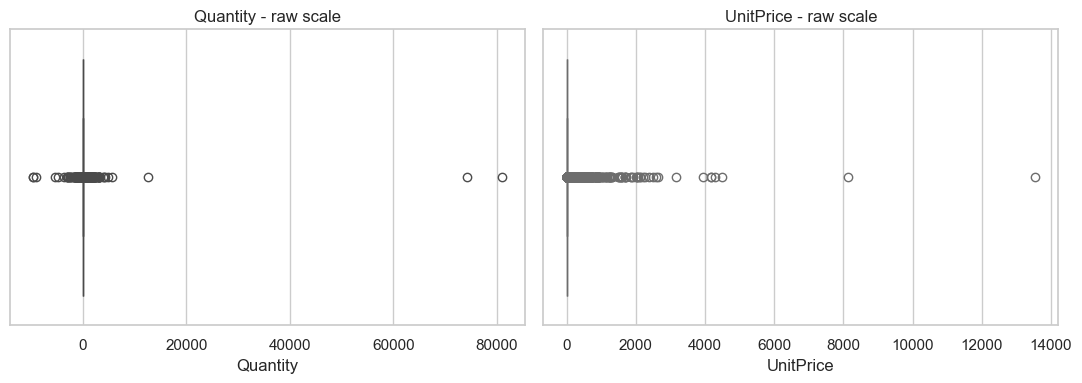

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(x=df_sales["Quantity"], ax=axes[0], color="steelblue")
axes[0].set_title("Quantity - raw scale")
sns.boxplot(x=df_sales["UnitPrice"], ax=axes[1], color="salmon")
axes[1].set_title("UnitPrice - raw scale")
plt.tight_layout()
plt.show()

In [ ]:
#Are the outliers real bulk orders, or errors?
# Look at the biggest quantity orders
big_orders = df_sales[df_sales["Quantity"] > 1000]
print(f"Rows with Quantity > 1000: {len(big_orders)}")

# Do the same customers show up repeatedly?
big_orders["CustomerID"].value_counts().head(10)

Rows with Quantity > 1000: 116


CustomerID
16333.0    16
0.0        10
17450.0     8
15749.0     8
12901.0     5
14646.0     5
16029.0     5
17949.0     4
16308.0     3
13694.0     3
Name: count, dtype: int64

In [ ]:
# Check unit price and product description on these large orders
big_orders[["CustomerID", "StockCode", "Description", "Quantity", "UnitPrice"]] \
    .sort_values("Quantity", ascending=False).head(20)

,CustomerID,StockCode,Description,Quantity,UnitPrice
531137,16446.0,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08
60580,12346.0,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04
493319,13256.0,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00
73250,0.0,37413,Missing_Description,5568,0.00
413862,12901.0,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21
202375,13135.0,22197,SMALL POPCORN HOLDER,4300,0.72
216863,0.0,85123A,?,4000,0.00
95589,18087.0,22053,EMPIRE DESIGN ROSETTE,3906,0.82
265917,14609.0,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06
51752,15749.0,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10


In [ ]:
df_sales[(df_sales["CustomerID"]==15749) & (df_sales["StockCode"]=="21108")]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
51752,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2011-01-11 12:55:00,2.1,15749.0,United Kingdom,6539.4
157576,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2011-04-18 13:20:00,2.1,15749.0,United Kingdom,6539.4


In [ ]:
#Correlation
corr = df_sales[["Quantity", "UnitPrice", "Revenue"]].corr()
corr

,Quantity,UnitPrice,Revenue
Quantity,1.000000,-0.003784,0.883635
UnitPrice,-0.003784,1.000000,0.125685
Revenue,0.883635,0.125685,1.000000


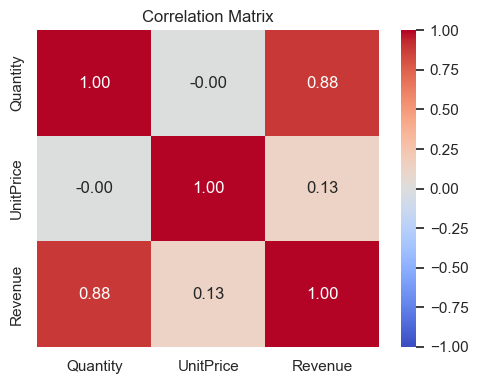

In [ ]:
plt.figure(figsize=(5, 4))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

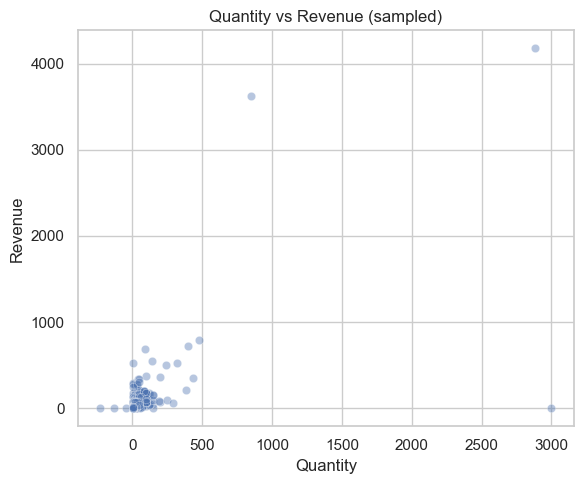

In [ ]:
sample = df_sales.sample(3000, random_state=42)  

plt.figure(figsize=(6, 5))
sns.scatterplot(data=sample, x="Quantity", y="Revenue", alpha=0.4)
plt.title("Quantity vs Revenue (sampled)")
plt.tight_layout()
plt.show()

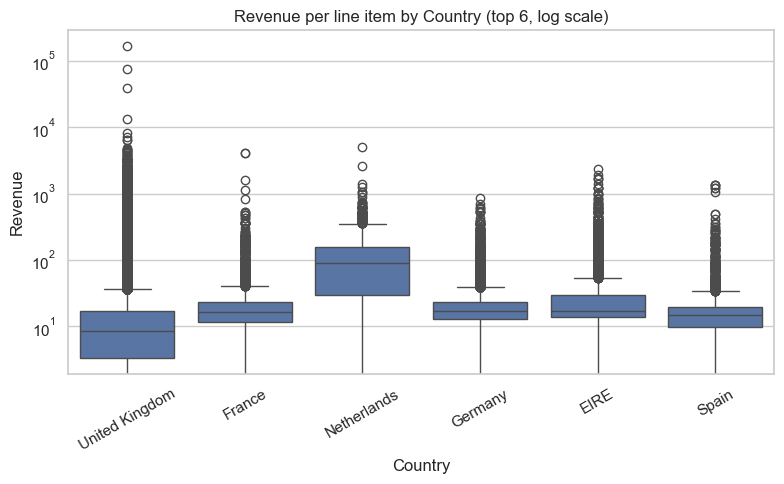

In [ ]:
# Compare Revenue by Country
top_countries = df_sales["Country"].value_counts().head(6).index
subset = df_sales[df_sales["Country"].isin(top_countries)]

plt.figure(figsize=(8, 5))
sns.boxplot(data=subset, x="Country", y="Revenue")
plt.yscale("log")
plt.title("Revenue per line item by Country (top 6, log scale)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show() 

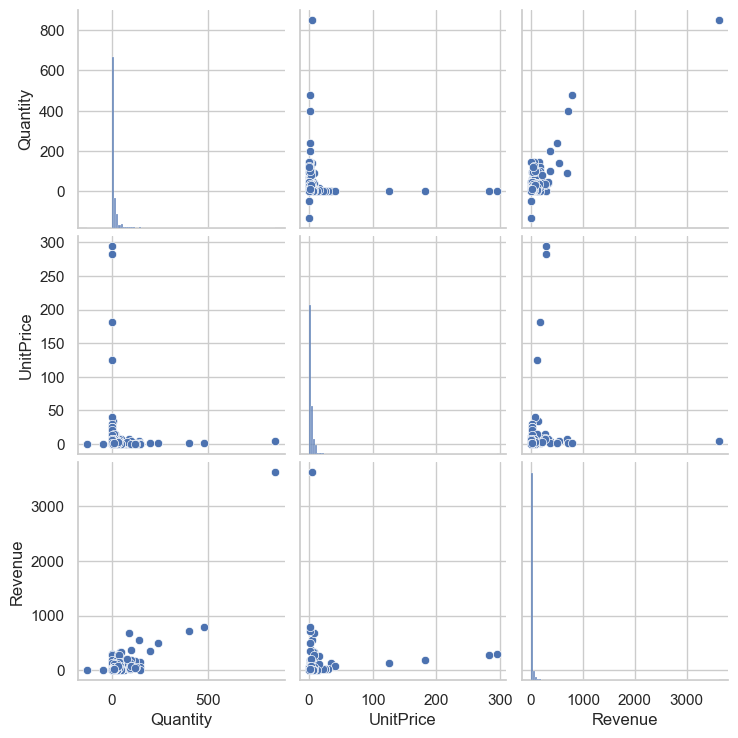

In [ ]:
pair_sample = df_sales[["Quantity", "UnitPrice", "Revenue"]].sample(2000, random_state=42)
sns.pairplot(pair_sample)
plt.show()

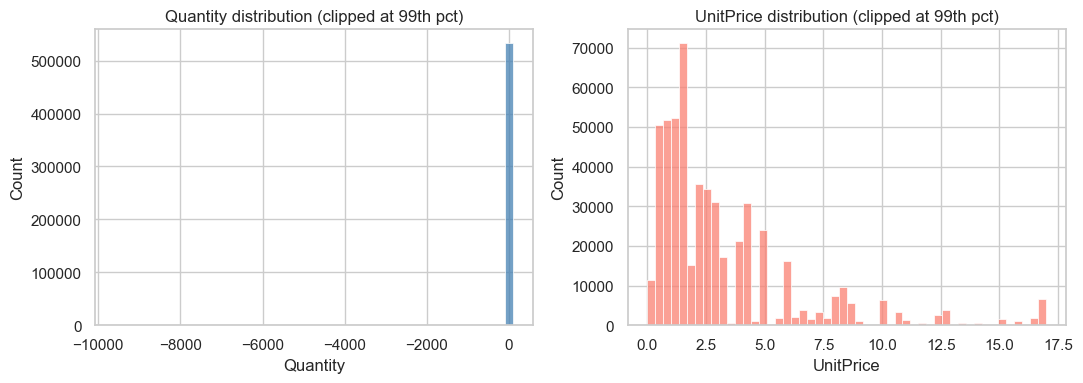

In [ ]:
#Histograms
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df_sales["Quantity"].clip(upper=df_sales["Quantity"].quantile(.99)), bins=50, ax=axes[0], color="steelblue")
axes[0].set_title("Quantity distribution (clipped at 99th pct)")
sns.histplot(df_sales["UnitPrice"].clip(upper=df_sales["UnitPrice"].quantile(.99)), bins=50, ax=axes[1], color="salmon")
axes[1].set_title("UnitPrice distribution (clipped at 99th pct)")
plt.tight_layout()
plt.show()

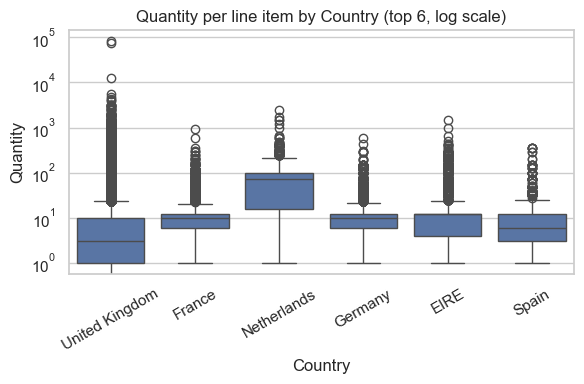

In [ ]:
#Box plots grouped by a category
plt.figure(figsize=(6, 4))
sns.boxplot(data=subset, x="Country", y="Quantity")
plt.yscale("log")
plt.title("Quantity per line item by Country (top 6, log scale)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [1]:
#Revenue over time
daily_revenue = df_sales.set_index("InvoiceDate").resample("D")["Revenue"].sum()
plt.figure(figsize=(10, 4))
daily_revenue.plot(color="darkorange")
plt.title("Daily Revenue Over Time")
plt.ylabel("Revenue (£)")
plt.tight_layout()
plt.show()

NameError: name 'df_sales' is not defined